In [1]:
import h5py
import matplotlib.pyplot as plt
import xarray as xr
import numpy as np

In [ ]:
hsrl_file = '/data/keeling/a/johntl3/b/LundstromPub2025/data/CAMP2Ex_HSRL/CAMP2EX-HSRL2_P3B_20191001_R0.h5'
f = h5py.File(hsrl_file, 'r')
print(list(f.keys()))
dps = f['DataProducts']
nav = f['Nav_Data']

['000_Readme', 'DataProducts', 'Nav_Data', 'State', 'UserInput', 'header']


In [ ]:
gps_time = nav['gps_time'][:,0]
gps_time[804:] += 24
hsrl_xr = xr.Dataset(coords=dict(gps_time=gps_time,
                                 altitude=dps['Altitude'][0,:]))
hsrl_xr['gps_alt'] = (['gps_time'], nav['gps_alt'][:,0])
hsrl_xr['gps_lat'] = (['gps_time'], nav['gps_lat'][:,0])
hsrl_xr['gps_lon'] = (['gps_time'], nav['gps_lon'][:,0])
hsrl_xr['ext532'] = (['gps_time', 'altitude'], dps['532_ext'][:])
hsrl_xr['ext355'] = (['gps_time', 'altitude'], dps['355_ext'][:])
hsrl_xr['ext1064'] = (['gps_time', 'altitude'], dps['1064_ext'][:])
hsrl_xr['Angstrom_532_355'] = (['gps_time', 'altitude'], dps['Angstrom_532_355'][:])
hsrl_xr['Angstrom_Dust'] = (['gps_time', 'altitude'], dps['Angstrom_Dust'][:])
hsrl_xr['Angstrom_Spherical'] = (['gps_time', 'altitude'], dps['Angstrom_Spherical'][:])

lam1 = 0.670
lam2 = 0.532
hsrl_xr['ext670_532_355'] = ((lam1/lam2)**(-hsrl_xr.Angstrom_532_355)) * hsrl_xr.ext532
hsrl_xr['ext670_Dust'] = ((lam1/lam2)**(-hsrl_xr.Angstrom_Dust)) * hsrl_xr.ext532
hsrl_xr['ext670_Spherical'] = ((lam1/lam2)**(-hsrl_xr.Angstrom_Spherical)) * hsrl_xr.ext532

ast_time = 24 + 2 + 39/60 + 30/60/60 # hours from midnight UTC (3 October 2019, 02:39:30)

# hsrl_xr.to_netcdf('../../dev/RF17_hsrl.nc')

In [4]:
hsrl_xr.isel(gps_time=slice(1400,2122))

<xarray.Dataset> Size: 23MB
Dimensions:             (gps_time: 722, altitude: 441)
Coordinates:
  * gps_time            (gps_time) float64 6kB 25.66 25.66 25.66 ... 27.66 27.66
  * altitude            (altitude) float64 4kB -500.0 -485.0 ... 6.095e+03
Data variables:
    gps_alt             (gps_time) float64 6kB 472.0 473.0 ... 4.813e+03
    gps_lat             (gps_time) float64 6kB 19.99 20.0 20.0 ... 20.42 20.43
    gps_lon             (gps_time) float64 6kB 120.7 120.7 120.7 ... 121.0 121.0
    ext532              (gps_time, altitude) float64 3MB nan nan nan ... nan nan
    ext355              (gps_time, altitude) float64 3MB nan nan nan ... nan nan
    ext1064             (gps_time, altitude) float64 3MB nan nan nan ... nan nan
    Angstrom_532_355    (gps_time, altitude) float64 3MB nan nan nan ... nan nan
    Angstrom_Dust       (gps_time, altitude) float64 3MB nan nan nan ... nan nan
    Angstrom_Spherical  (gps_time, altitude) float64 3MB nan nan nan ... nan nan
    ext670_532_355      (gps_time, altitude) float64 3MB nan nan nan ... nan nan
    ext670_Dust         (gps_time, altitude) float64 3MB nan nan nan ... nan nan
    ext670_Spherical    (gps_time, altitude) float64 3MB nan nan nan ... nan nan

In [5]:
ast_time

26.65833333333333

/tmp/ipykernel_160818/1331294030.py:6: RuntimeWarning: Mean of empty slice
  ax.plot(np.nanmean(data, axis=0), hsrl_xr.altitude, c='orange', linewidth=4, alpha=0.7)
/tmp/ipykernel_160818/1331294030.py:7: RuntimeWarning: Mean of empty slice
  ax.plot(np.nanmean(data, axis=0) - np.nanstd(data, axis=0), hsrl_xr.altitude, c='orange', linewidth=4, alpha=0.7, ls='--')
/data/keeling/a/johntl3/miniconda3/envs/hsrl/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:2035: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/tmp/ipykernel_160818/1331294030.py:8: RuntimeWarning: Mean of empty slice
  ax.plot(np.nanmean(data, axis=0) + np.nanstd(data, axis=0), hsrl_xr.altitude, c='orange', linewidth=4, alpha=0.7, ls='--')


Text(0, 0.5, 'altitude [m]')

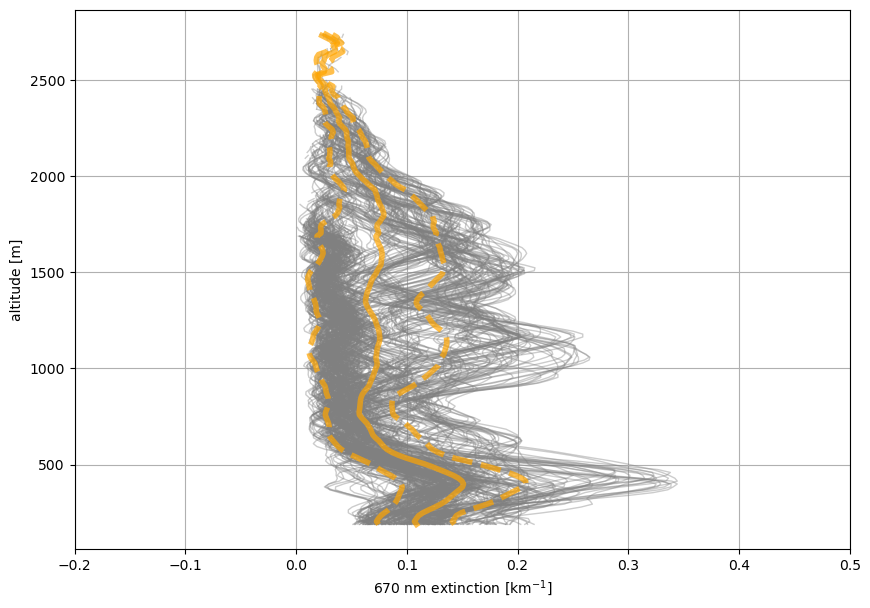

In [6]:
data = hsrl_xr.isel(gps_time=slice(1400,2122)).ext670_532_355.data
data[data < 0] = np.nan
f, ax = plt.subplots(1, 1, figsize=(10, 7))
for i in range(data.shape[0]):
    ax.plot(data[i,:], hsrl_xr.altitude, c='grey', linewidth=1, alpha=0.4)
ax.plot(np.nanmean(data, axis=0), hsrl_xr.altitude, c='orange', linewidth=4, alpha=0.7)
ax.plot(np.nanmean(data, axis=0) - np.nanstd(data, axis=0), hsrl_xr.altitude, c='orange', linewidth=4, alpha=0.7, ls='--')
ax.plot(np.nanmean(data, axis=0) + np.nanstd(data, axis=0), hsrl_xr.altitude, c='orange', linewidth=4, alpha=0.7, ls='--')

ax.set_xlim([-0.2, 0.5])
ax.grid()
ax.set_xlabel('670 nm extinction [km$^{-1}$]')
ax.set_ylabel('altitude [m]')

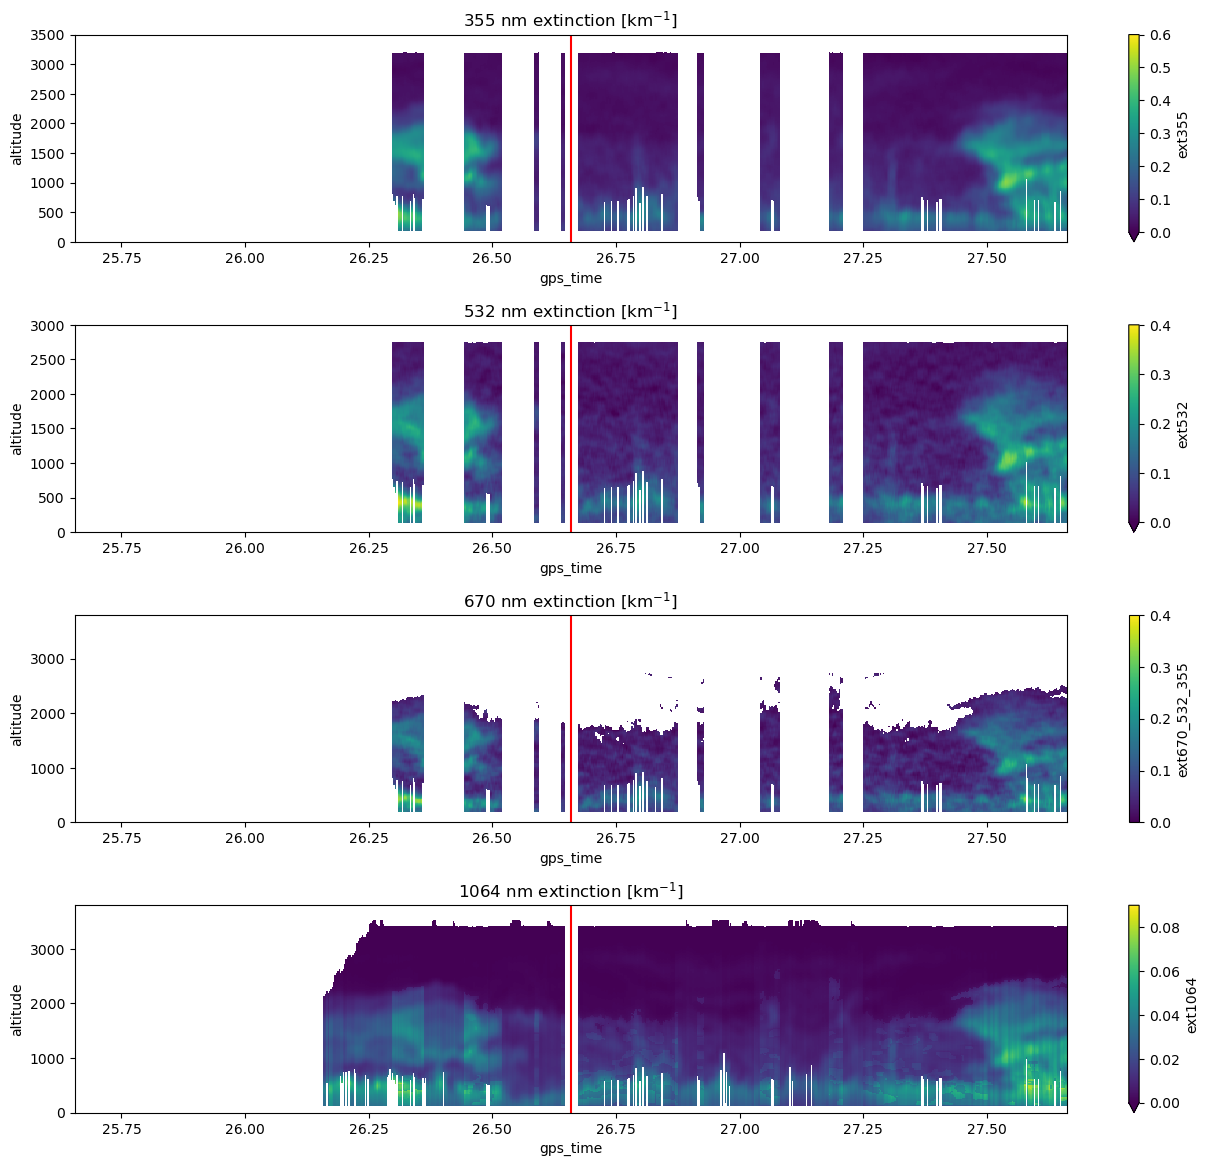

In [7]:
f, ax = plt.subplots(4, 1, figsize=(16, 14))
hsrl_tmp = hsrl_xr.isel(gps_time=slice(1400,2122)).copy(deep=True)

hsrl_tmp.ext355.plot(y='altitude', ax=ax[0], vmin=0, vmax=0.6)
ax[0].vlines(x=ast_time, ymin=0, ymax=4000, colors='r')
ax[0].set_ylim([0, 3500])
ax[0].set_title('355 nm extinction [km$^{-1}$]')

hsrl_tmp.ext532.plot(y='altitude', ax=ax[1], vmin=0, vmax=0.4)
ax[1].vlines(x=ast_time, ymin=0, ymax=4000, colors='r')
ax[1].set_ylim([0, 3000])
ax[1].set_title('532 nm extinction [km$^{-1}$]')

hsrl_tmp.ext670_532_355.plot(y='altitude', ax=ax[2], vmin=0, vmax=0.4)
# hsrl_tmp.ext670_Dust.plot(y='altitude', ax=ax[2], vmin=0, vmax=0.4)
# hsrl_tmp.ext670_Spherical.plot(y='altitude', ax=ax[2], vmin=0, vmax=0.4)
ax[2].vlines(x=ast_time, ymin=0, ymax=4000, colors='r')
ax[2].set_ylim([0, 3800])
ax[2].set_title('670 nm extinction [km$^{-1}$]')

hsrl_tmp.ext1064.plot(y='altitude', ax=ax[3], vmin=0, vmax=0.09)
ax[3].vlines(x=ast_time, ymin=0, ymax=4000, colors='r')
ax[3].set_ylim([0, 3800])
ax[3].set_title('1064 nm extinction [km$^{-1}$]')

f.subplots_adjust(hspace=0.4)

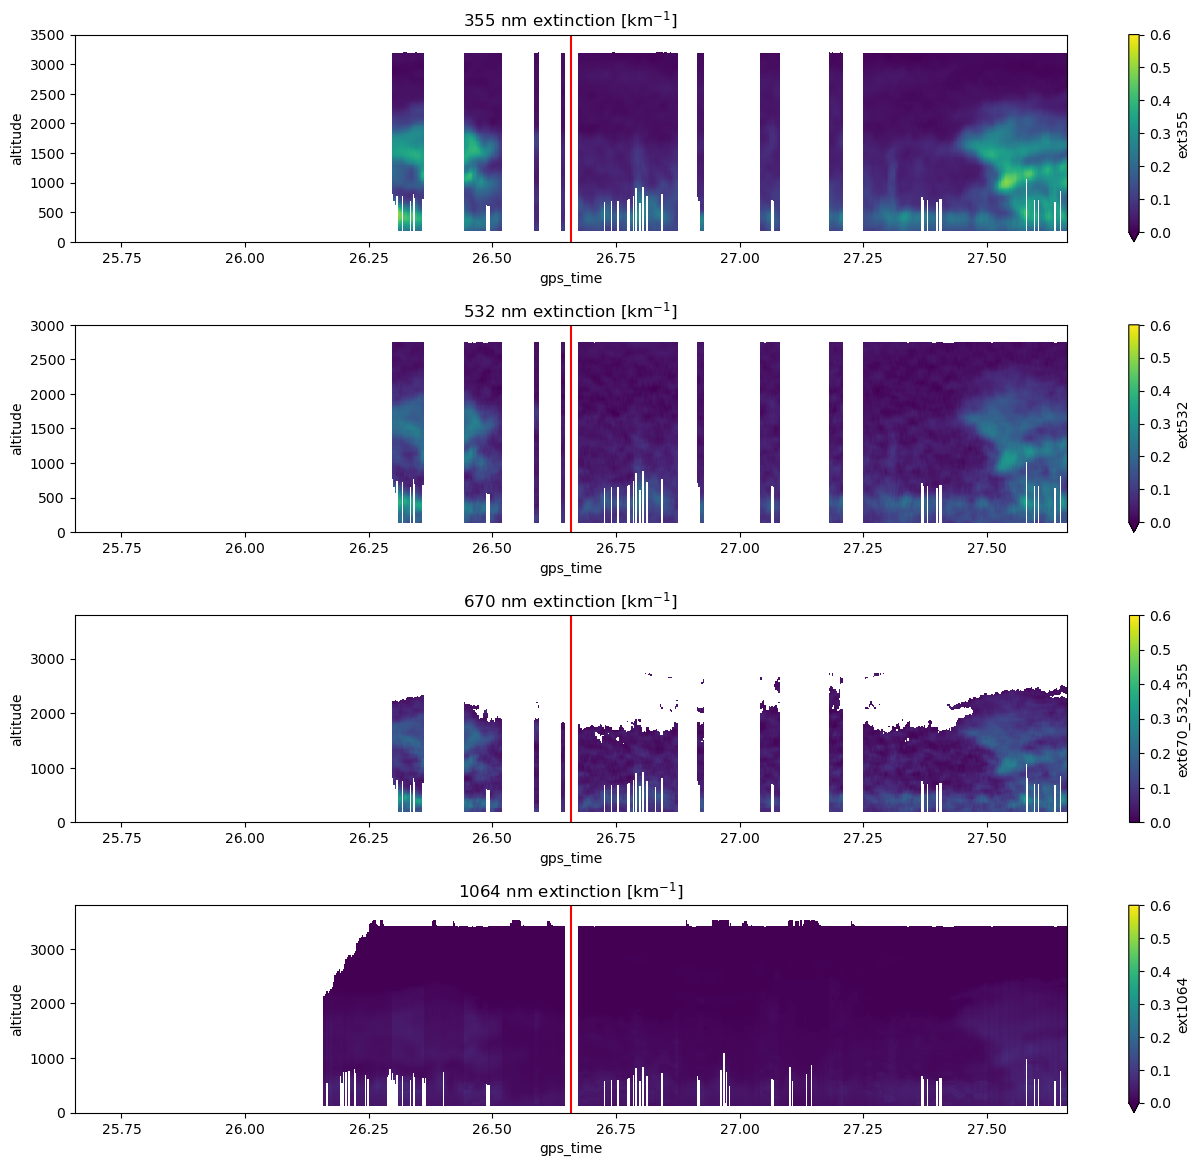

In [8]:
f, ax = plt.subplots(4, 1, figsize=(16, 14))
hsrl_tmp = hsrl_xr.isel(gps_time=slice(1400,2122)).copy(deep=True)

hsrl_tmp.ext355.plot(y='altitude', ax=ax[0], vmin=0, vmax=0.6)
ax[0].vlines(x=ast_time, ymin=0, ymax=4000, colors='r')
ax[0].set_ylim([0, 3500])
ax[0].set_title('355 nm extinction [km$^{-1}$]')

hsrl_tmp.ext532.plot(y='altitude', ax=ax[1], vmin=0, vmax=0.6)
ax[1].vlines(x=ast_time, ymin=0, ymax=4000, colors='r')
ax[1].set_ylim([0, 3000])
ax[1].set_title('532 nm extinction [km$^{-1}$]')

hsrl_tmp.ext670_532_355.plot(y='altitude', ax=ax[2], vmin=0, vmax=0.6)
# hsrl_tmp.ext670_Dust.plot(y='altitude', ax=ax[2], vmin=0, vmax=0.6)
# hsrl_tmp.ext670_Spherical.plot(y='altitude', ax=ax[2], vmin=0, vmax=0.6)
ax[2].vlines(x=ast_time, ymin=0, ymax=4000, colors='r')
ax[2].set_ylim([0, 3800])
ax[2].set_title('670 nm extinction [km$^{-1}$]')

hsrl_tmp.ext1064.plot(y='altitude', ax=ax[3], vmin=0, vmax=0.6)
ax[3].vlines(x=ast_time, ymin=0, ymax=4000, colors='r')
ax[3].set_ylim([0, 3800])
ax[3].set_title('1064 nm extinction [km$^{-1}$]')

f.subplots_adjust(hspace=0.4)

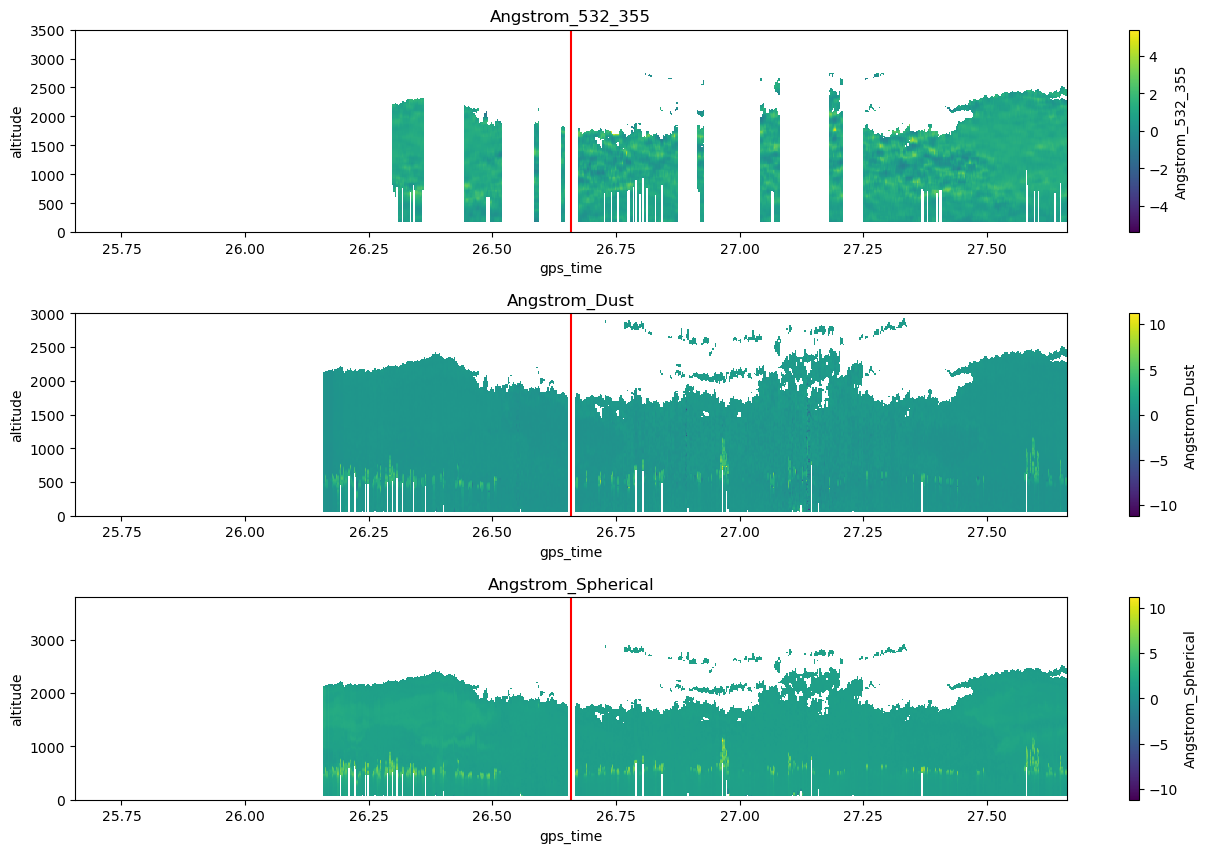

In [9]:
f, ax = plt.subplots(3, 1, figsize=(16, 10))
hsrl_tmp = hsrl_xr.isel(gps_time=slice(1400,2122)).copy(deep=True)

hsrl_tmp.Angstrom_532_355.plot(y='altitude', ax=ax[0], cmap='viridis')
ax[0].vlines(x=ast_time, ymin=0, ymax=4000, colors='r')
ax[0].set_ylim([0, 3500])
ax[0].set_title('Angstrom_532_355')

hsrl_tmp.Angstrom_Dust.plot(y='altitude', ax=ax[1], cmap='viridis')
ax[1].vlines(x=ast_time, ymin=0, ymax=4000, colors='r')
ax[1].set_ylim([0, 3000])
ax[1].set_title('Angstrom_Dust')

hsrl_tmp.Angstrom_Spherical.plot(y='altitude', ax=ax[2], cmap='viridis')
ax[2].vlines(x=ast_time, ymin=0, ymax=4000, colors='r')
ax[2].set_ylim([0, 3800])
ax[2].set_title('Angstrom_Spherical')

f.subplots_adjust(hspace=0.4)